## Simulation

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_model_static
%aimport quantdata.dysanos.grid.torch_model_pca
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig

grid_config     = GridConfig(grid_num_strikes=100)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training 20-ac-SELU version 0.3 group 'sm25_100' for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 400 samples with learning rate 0.0001 and weight decay 1e-06.
01:   Model config: 20-ac-SELU@.sm25_100 0.3 0.25-smooth sample,mvsq=0.0001 nms=20,(-2.00,1.00) dlv=(0.01,3.00),fvol=(0.01,2.00) state=20@FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,19.8,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2,msqv=0.0001
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-ac-SELU version 0.3 on Env(prec=32,device=cuda,debug=False)... done; this took 3s.
00: Instantiating 20-ac-SELU version 0.3 on Env(prec=32,device=cuda

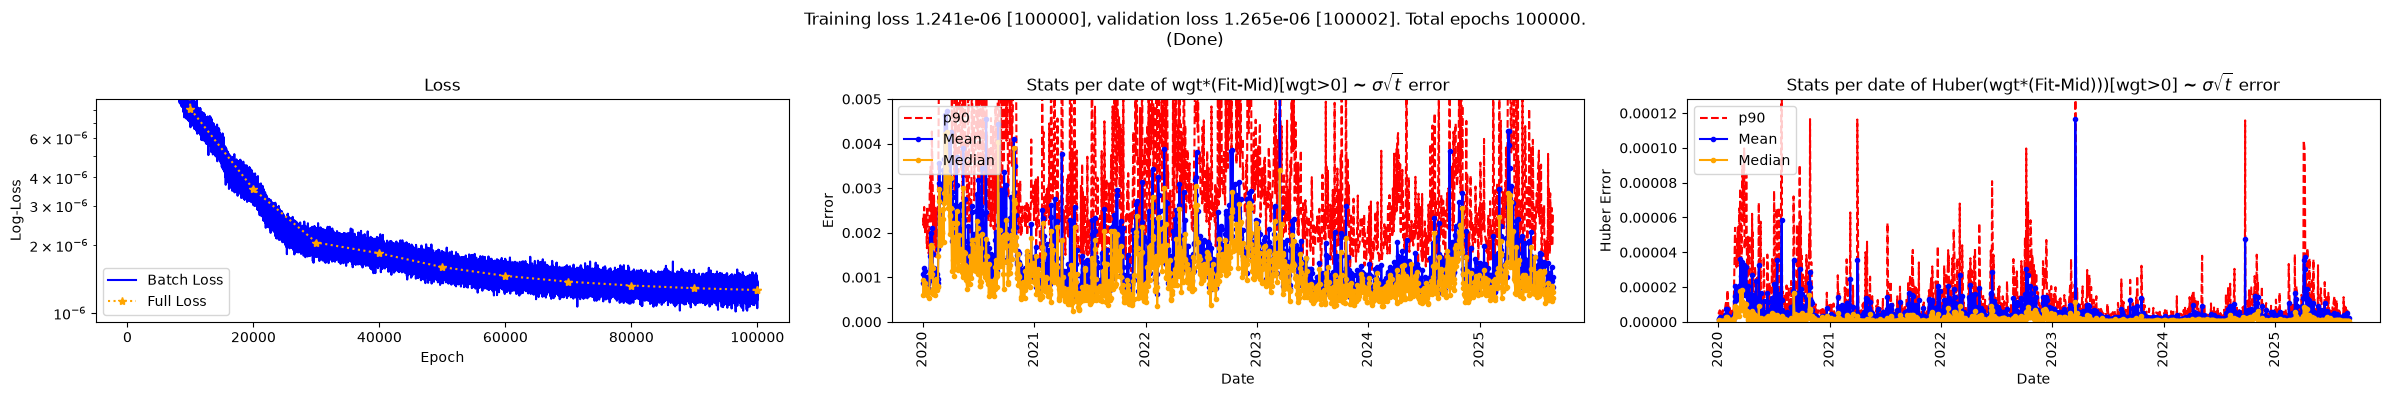

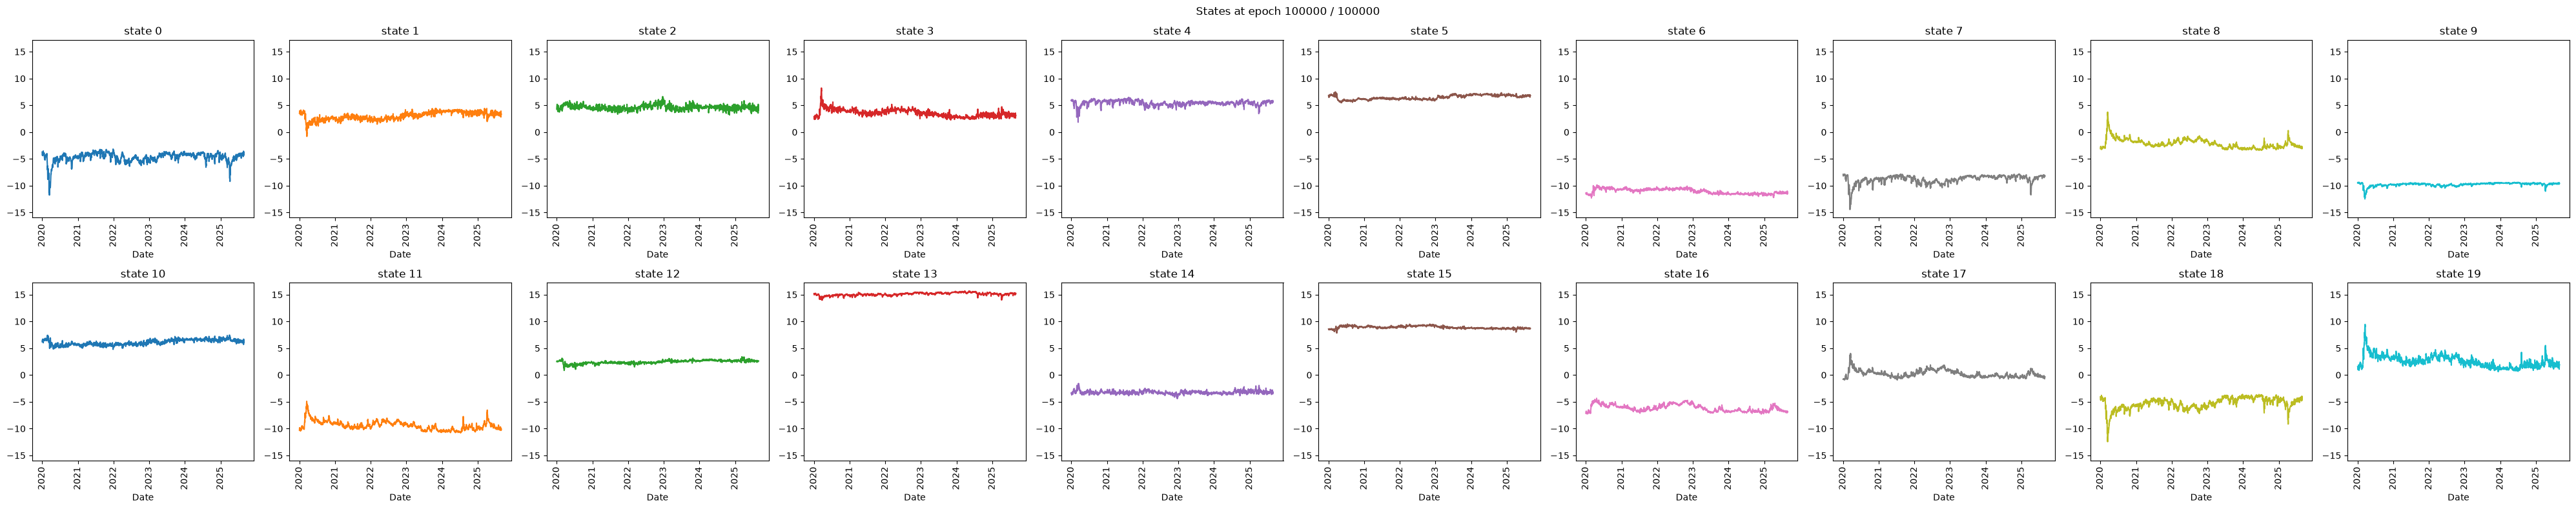

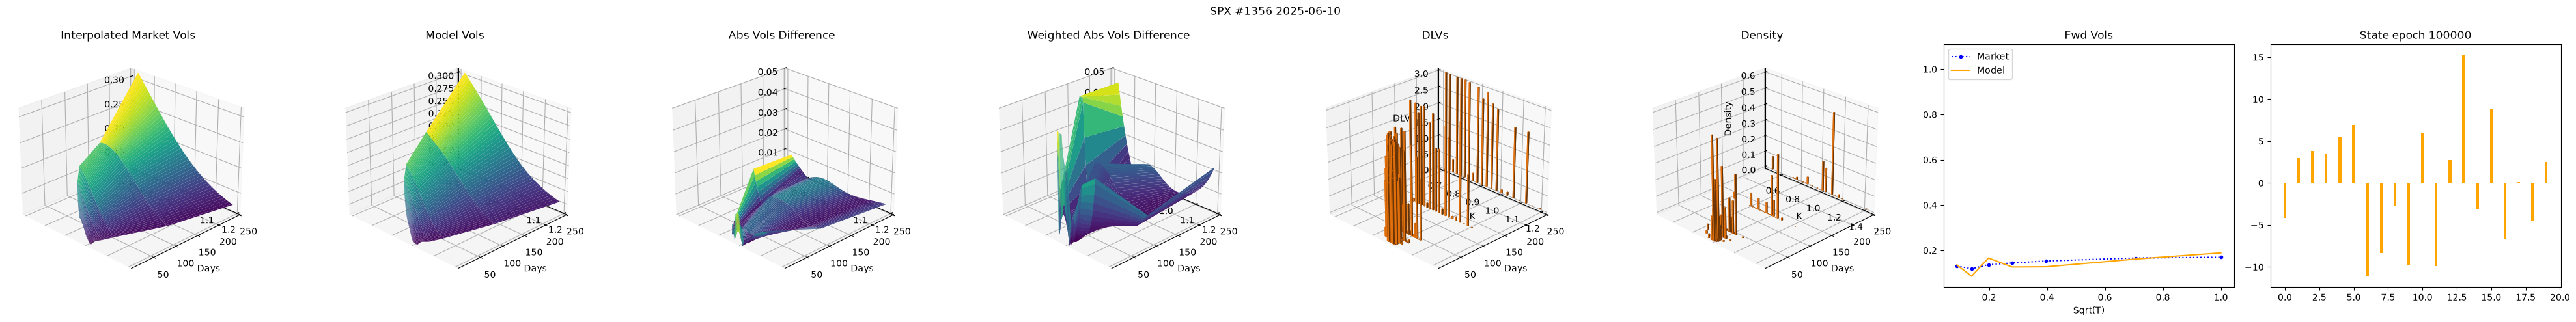

/home/hans/vqdata/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


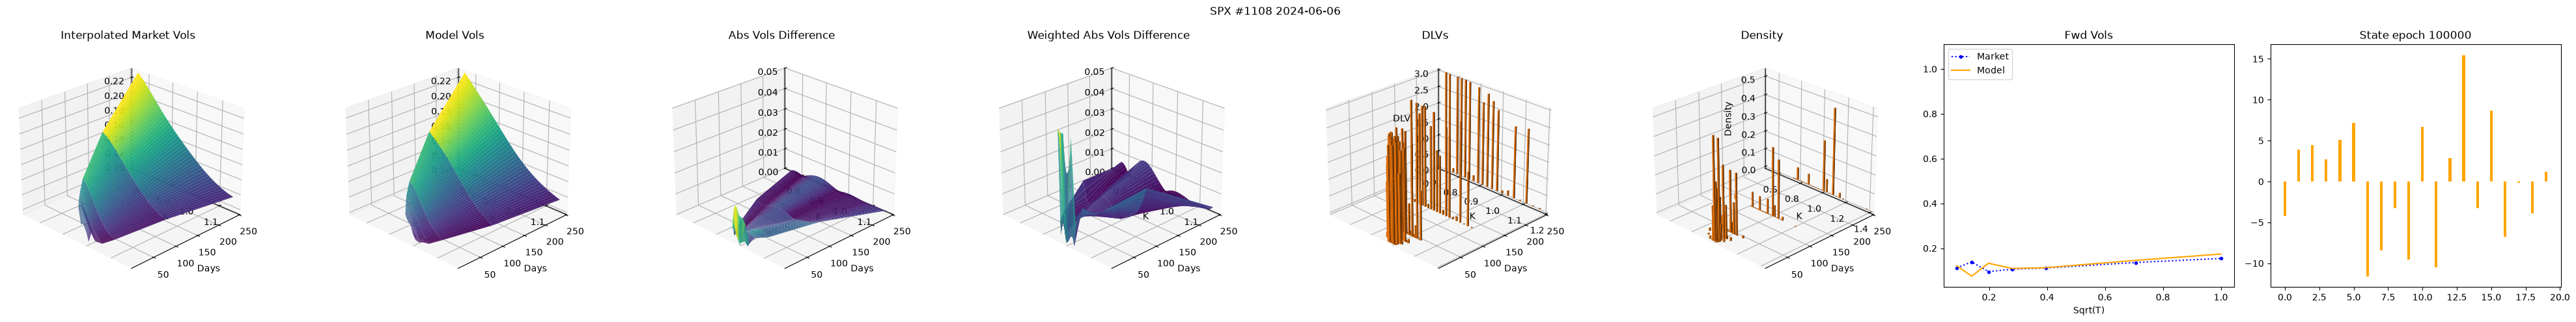

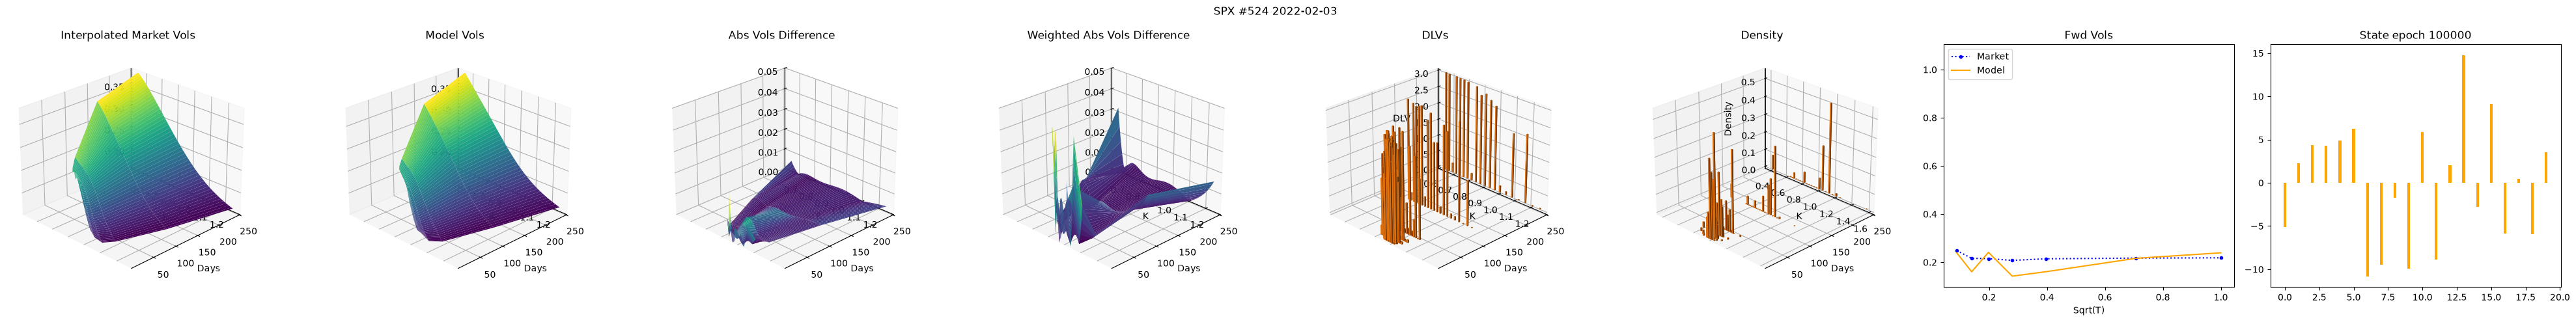

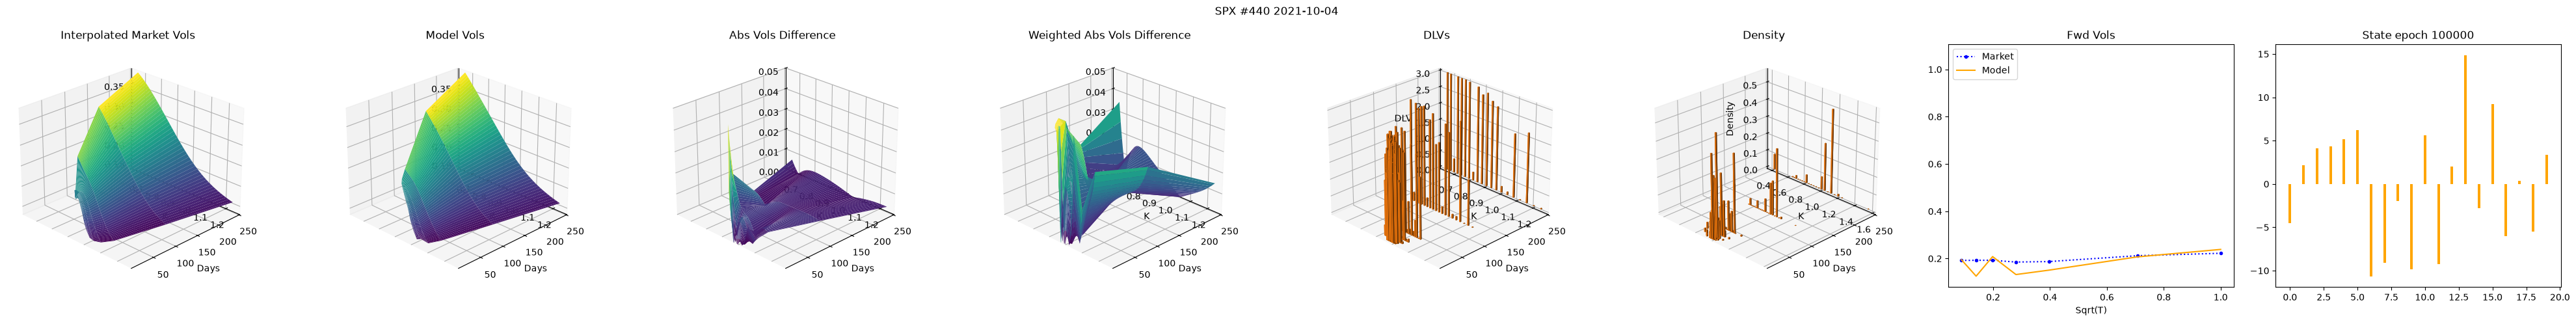

00: Model 20-ac-SELU version 0.3 group 'sm25_100' trained for 100000 epochs. Final training loss: 1.241e-06, valuation loss: 1.265e-06. This took 9s.
00: Checkpoint file is /home/hans/.dysanos_grid/sm25_100/20-ac-SELU f5aa8325.pt.
/done


In [2]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model_static import BaseEnvironment, FeedForward, SanosCompressorConfig
import numpy as np

mdl_config = SanosCompressorConfig( 
    user_version="0.3",
    label="20-ac-SELU",
    group="sm25_100",
    smoothness = 0.25,
    num_state = 20, 
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
)
viz_config = VizConfig( num_viz_dates=4 )
trn_config = TrainConfig( num_epochs=100_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-6, batch_size=400, compile=True, epoch_interval=10000 )
r, model, tdata = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config )
print("/done")

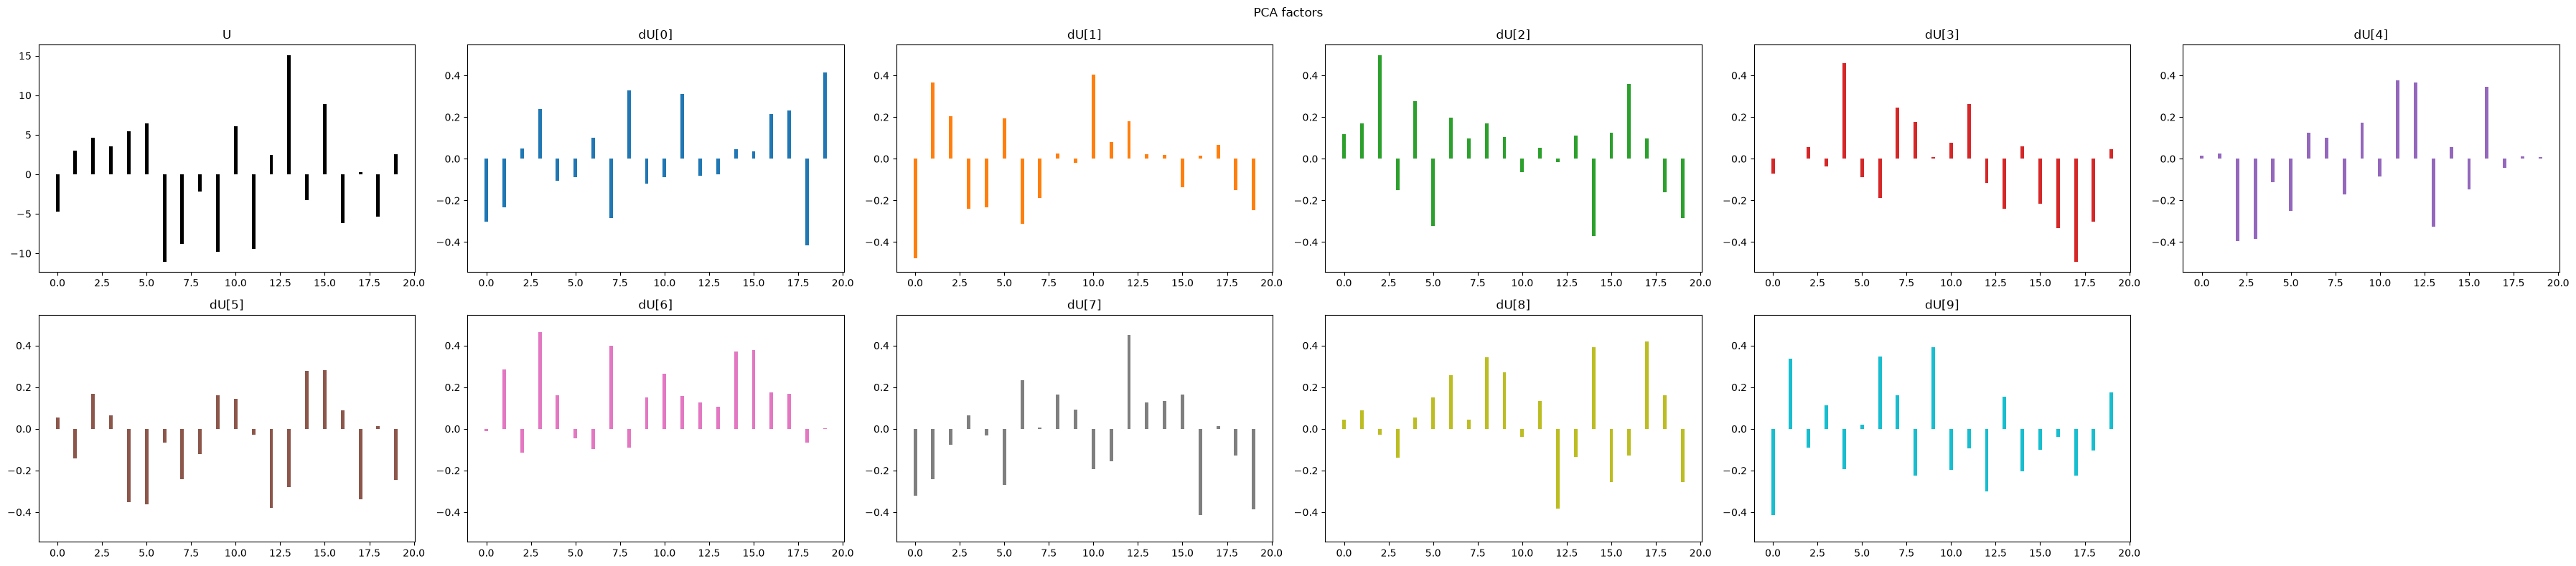

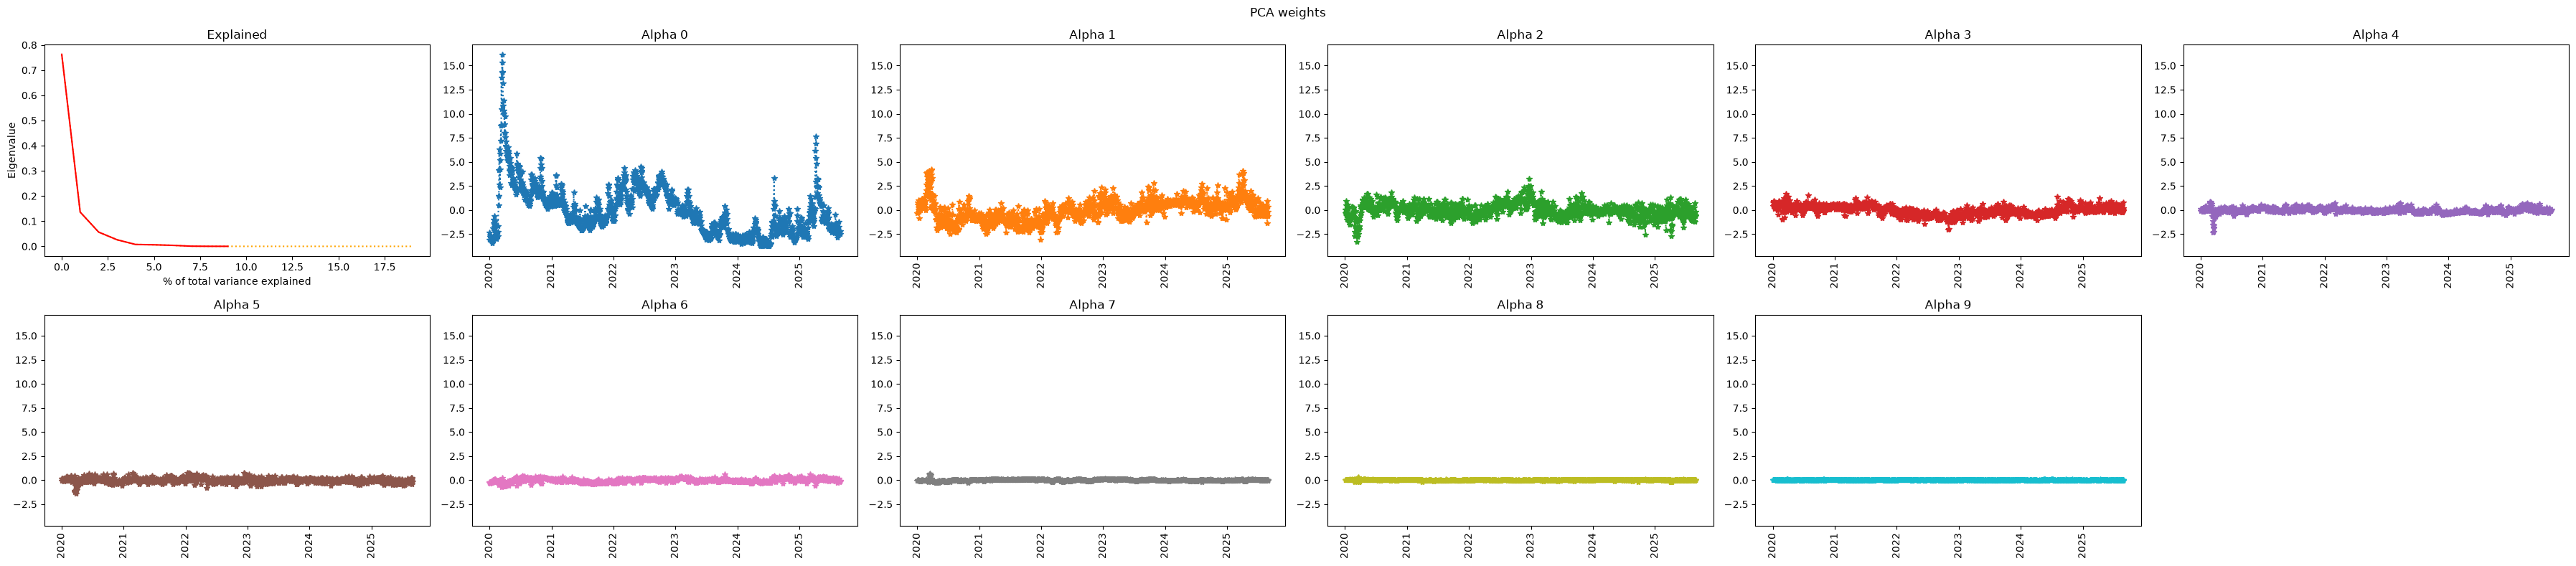

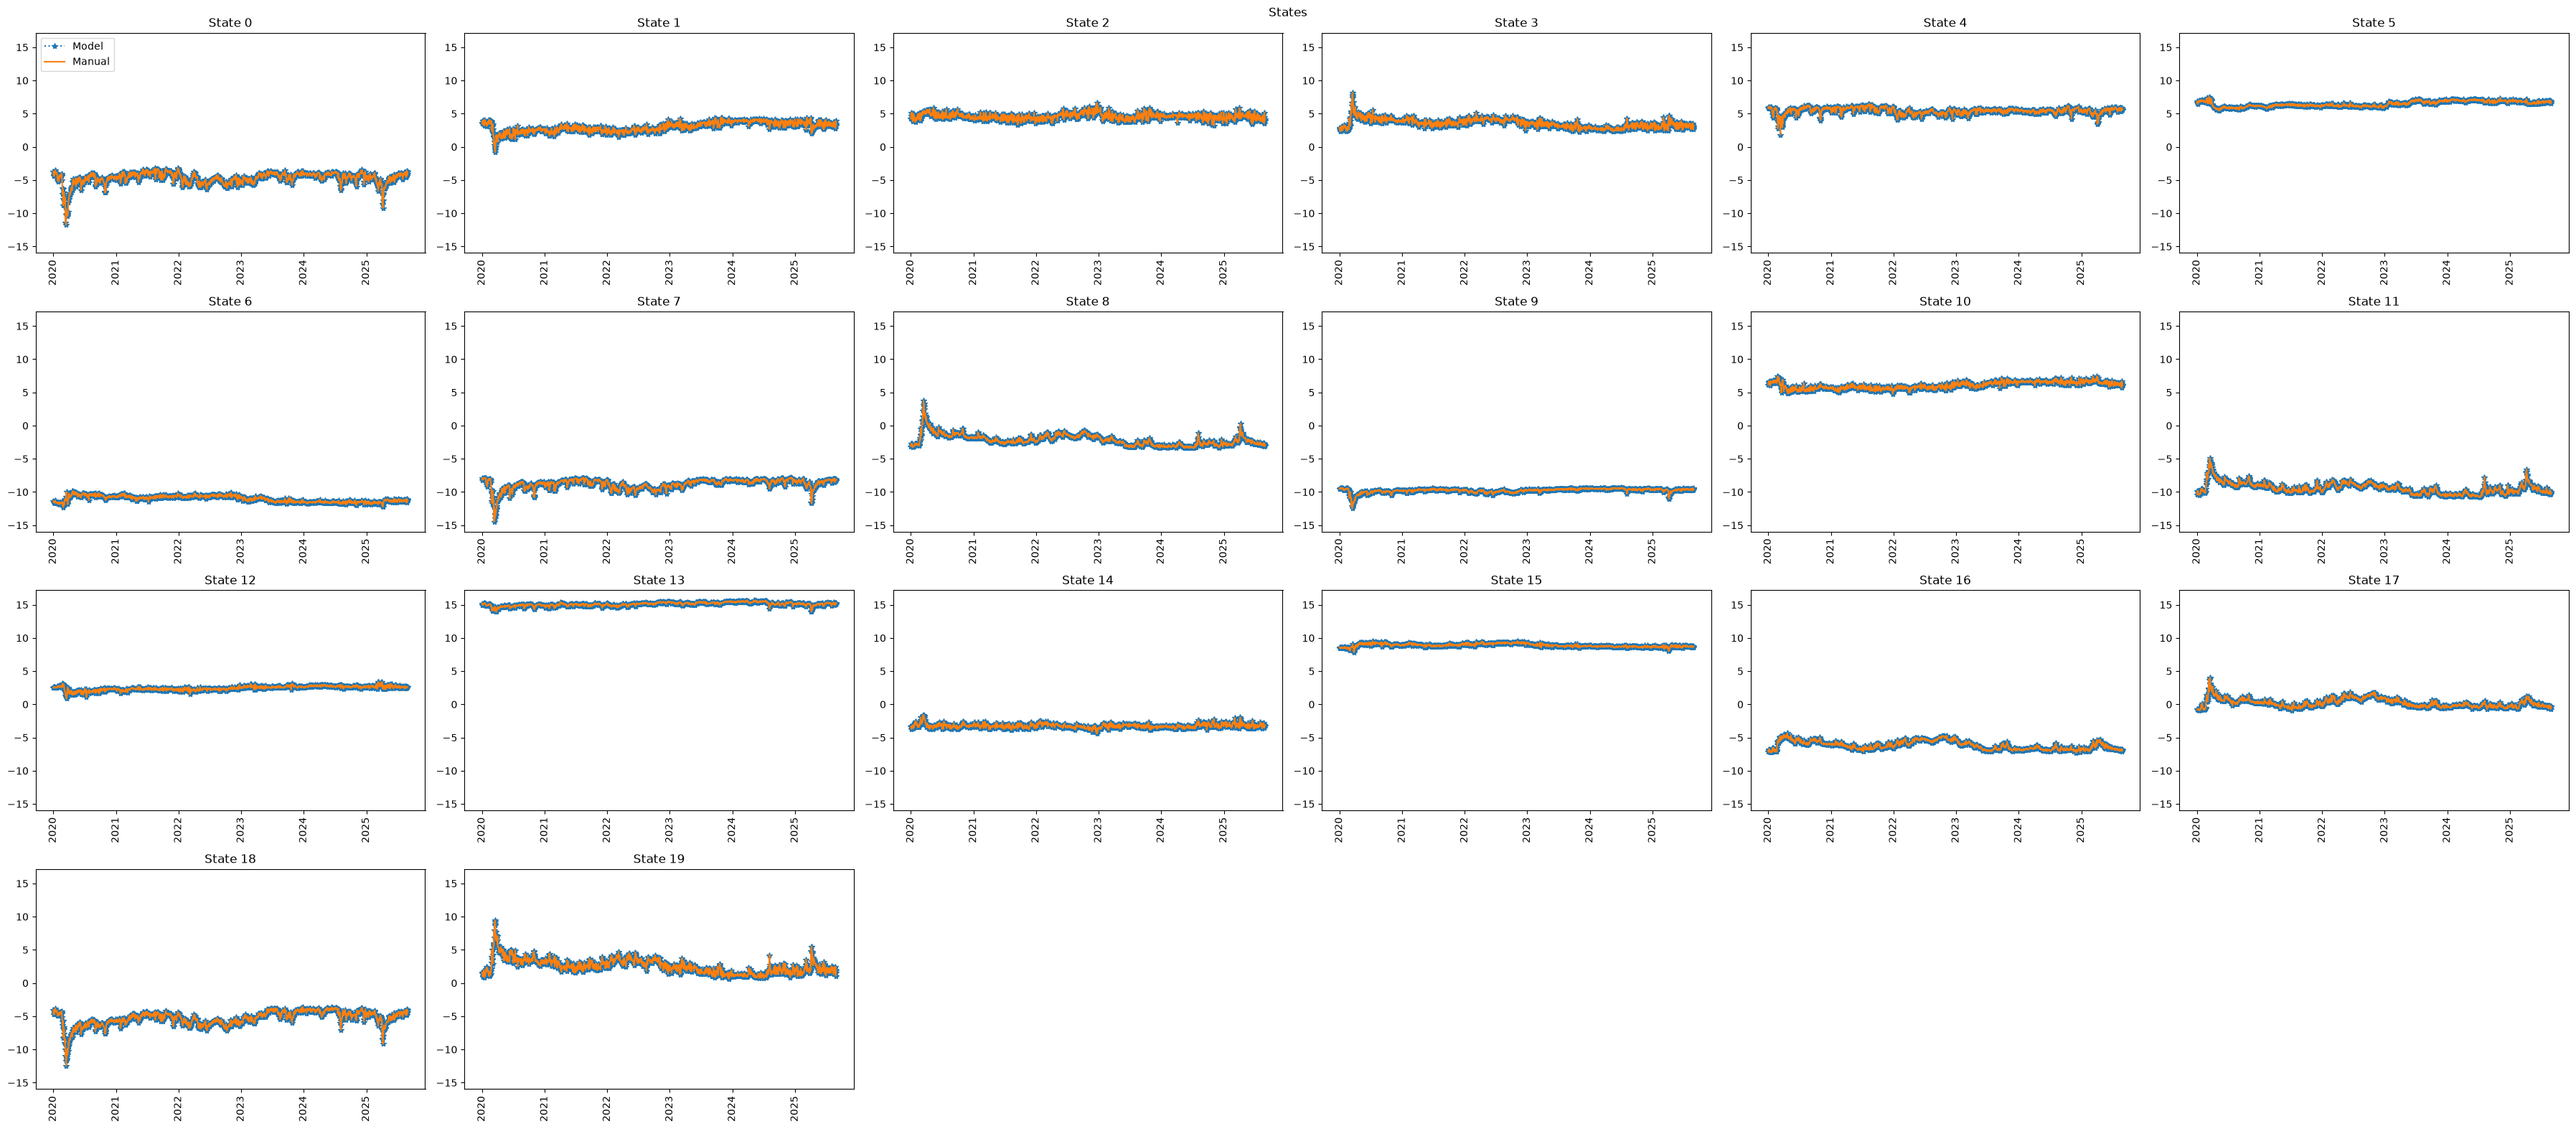

In [3]:
from cdxcore.dynaplot import figure, colors_tableau, m_o_m
import numpy as np

def plot_stuff(*,draw_pca_factors=True, draw_pca_alpha=True, draw_states=True):
    dates = market.dates
    ld = model(tdata, training=False)
    ld = { k: v.detach().cpu().numpy() for k, v in ld.items() if not v is None }

    T         = len(dates)
    state     = ld['state']
    num_state = state.shape[-1]
    num_alpha = 10
    
    # manual PCA
    def pca_():
        mu0    = np.mean(state, axis=0, keepdims=True)
        Xc     = state - mu0
        U, SD, Vt = np.linalg.svd(Xc, full_matrices=False)
        mdu   = Vt[:num_alpha]               # shape (K, M), orthonormal rows
        assert mdu.shape == (num_alpha,num_state)
        alpha2 = U[:, :num_alpha] * SD[:num_alpha]     # shape (T, num_alpha)
        ev        = SD**2
        return alpha2, np.concatenate( [mu0, mdu], axis=0 ), ev
    malpha, mu_du, mev = pca_()
    
    if draw_pca_factors:
        def draw(label, u_du):
            with figure(label + " factors", row_size=4, col_size=6, columns=6 ) as fig:
                ax_ = None
                colors = colors_tableau()
                for i in range(u_du.shape[0]):
                    ax = fig.add_subplot("U" if i==0 else f"dU[{i-1}]")
                    ax.bar( np.arange(u_du.shape[1]), u_du[i,:], width=0.2, color="black" if i==0 else next(colors))
                    if i>0:
                        if not ax_ is None:
                            ax.sharey(ax_)
                        else:
                            ax_ = ax
                ax_.set_ylim( m_o_m( u_du[1:,:] ) )
        draw("PCA", mu_du)
    
    if draw_pca_alpha:
        def draw( label, alpha ):
            with figure(label + " weights", row_size=4, col_size=6, columns=6 ) as fig:
                ax = fig.add_subplot("Explained")
                ax.plot( np.arange(0,len(mev)), mev/np.sum(mev), ":", color="orange", label="All")
                ax.plot( np.arange(0,num_alpha), mev[:num_alpha]/np.sum(mev), "-", color="red",label=f"First {num_alpha}")
                ax.set_xlabel("% of total variance explained")
                ax.set_ylabel("Eigenvalue")
                
                ax_ = None
                colors = colors_tableau()
                for i in range(alpha.shape[1]):
                    ax = fig.add_subplot(f"Alpha {i}")
                    ax.plot( dates, alpha[:,i], "*:", label="Model", color=next(colors))
                    ax.tick_params(axis="x", labelrotation=90)
                    if not ax_ is None:
                        ax.sharey(ax_)
                    else:
                        ax_ = ax
                ax_.set_ylim( m_o_m(alpha) )
        draw("PCA", malpha)

    if draw_states:
        with figure("States", row_size=4, col_size=6, columns=6 ) as fig:
            ax_ = None
            colors = colors_tableau()
            for i in range(state.shape[1]):
                ax = fig.add_subplot(f"State {i}")
                ax.plot( dates, state[:,i], "*:", label="Model")
                ax.plot( dates, state[:,i], label="Manual")
                ax.tick_params(axis="x", labelrotation=90)
                ax.legend(loc="upper left") if i==0 else None
                if not ax_ is None:
                    ax.sharey(ax_)
                else:
                    ax_ = ax
            ax_.set_ylim( m_o_m(state) )




plot_stuff()




00: Model 20-ac-SELU@.sm25_100 0.3: using 20 factors for 20 states over 1412 dates. The 20 factors explain 100% of variance.


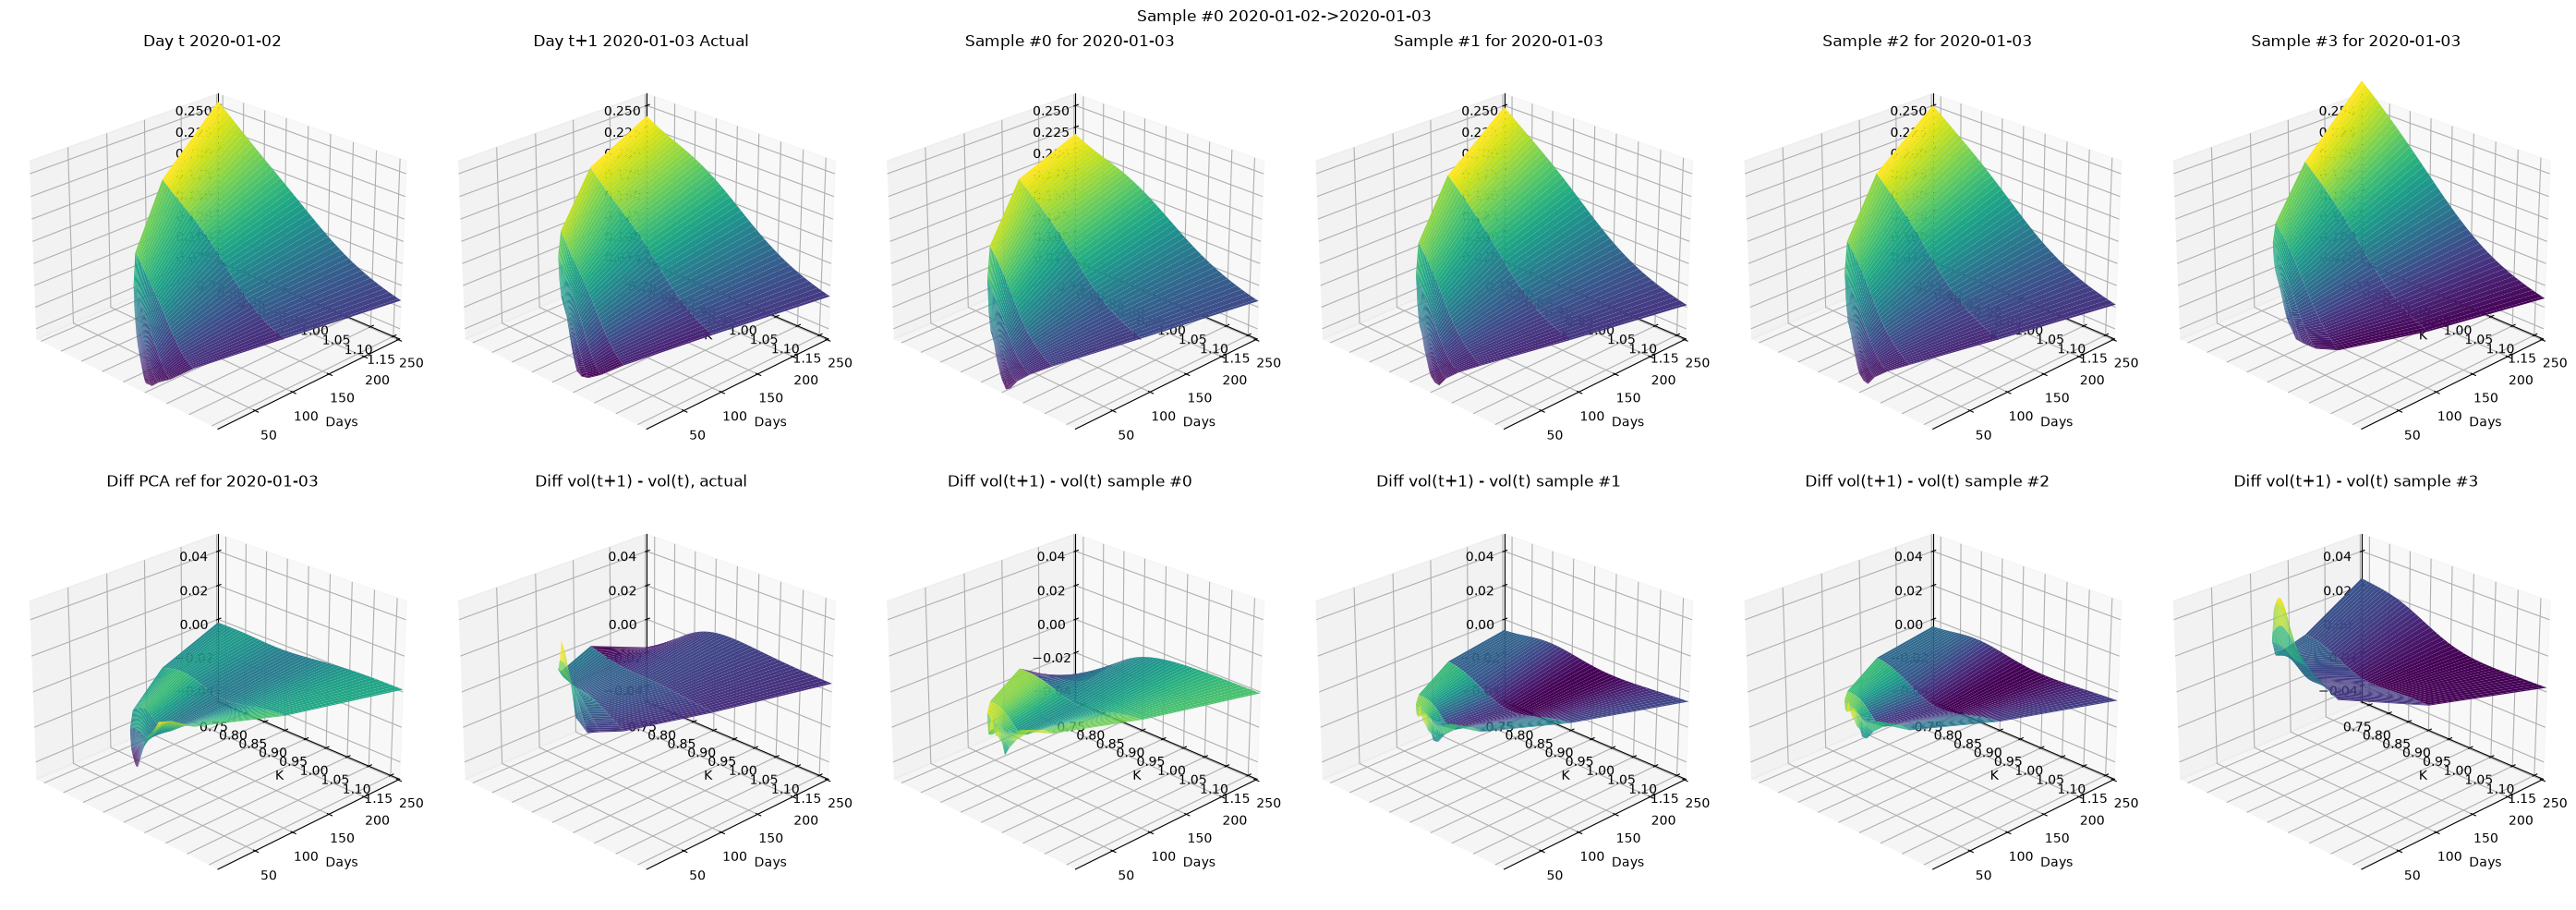

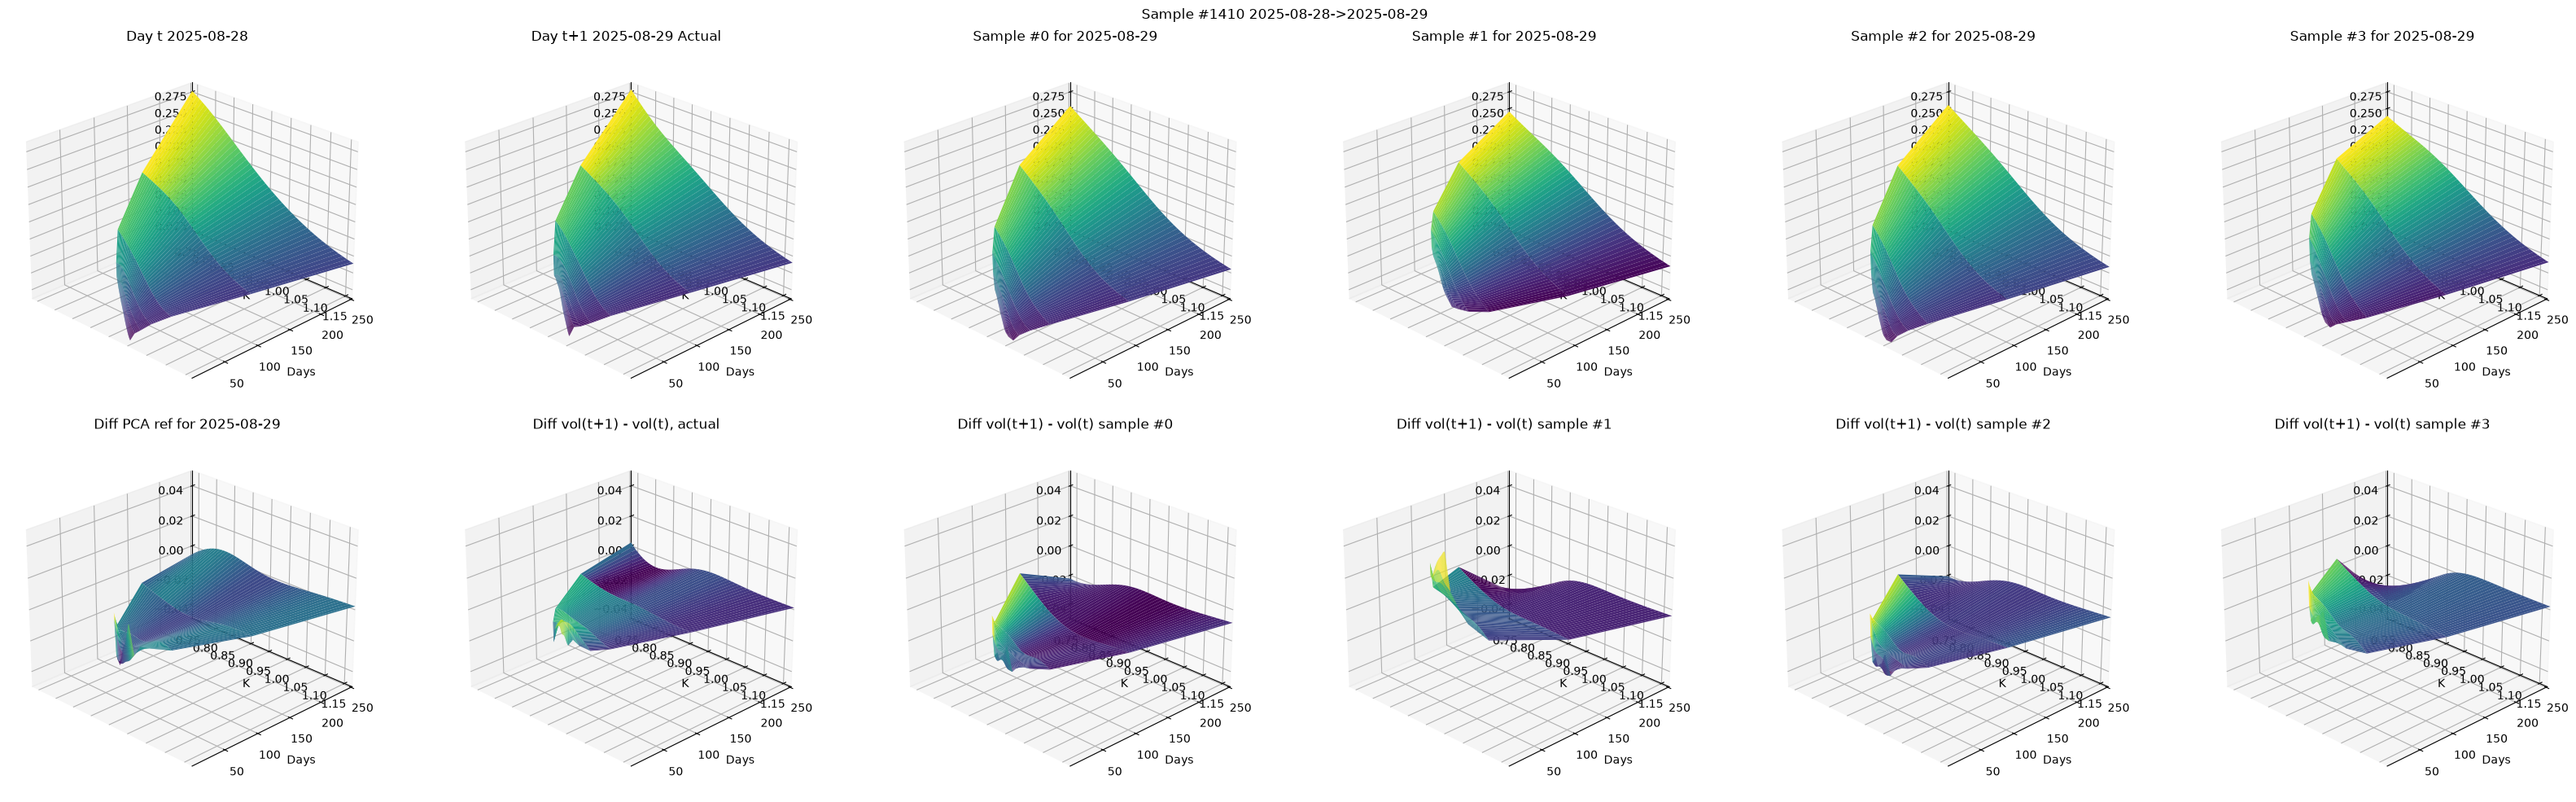

KeyboardInterrupt: 

In [9]:
from dataclasses import dataclass
from cdxcore.err import verify_inp
from cdxcore.verbose import Context
from cdxcore.pretty import PrettyObject
from quantdata.dysanos.grid.torch_simulator import NormalSamplerConfig, NormalSampler
from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.torch import BaseEnvironment
from cdxcore.dynaplot import figure, FigStore
import torch
import numpy as np
from cdxcore.bs import bs
import time

def plot_vol( ax, expiries, strikes, vols, *, store = None, first = True ):
    exp_block = np.stack( [ expiries*DAYS_PER_YEAR ]*(strikes.shape[-1]), axis=-1 )
    exp_range = (expiries.max()*DAYS_PER_YEAR, expiries.min()*DAYS_PER_YEAR)
    
    r = ax.plot_surface( exp_block, strikes, vols, cmap='viridis', edgecolor='none')
    if not store is None:
        store += r
    if first or True:
        ax.set_xlabel("Days")
        ax.set_ylabel("K")
        ax.view_init(elev=25, azim=45) 
        ax.set_xlim(*exp_range)
        ax.set_ylim( strikes.min(), strikes.max() )

def simulate_1( indices, num_samples=4 ):
    env            = BaseEnvironment()
    ns_config      = NormalSamplerConfig(num_alpha=-1, bandwidth=0.05)
    normal_sampler = NormalSampler( model=model, market=market, tdata=tdata, config=ns_config )

    figures   = []
    sim_axs   = {}
    store     = FigStore()
    orig_vols = {}

    markets   = []
    
    def vols_for_state( state, index_tdata, expiries, strikes ):
        assert len(state.shape) == 1
        index_state        = torch.tensor( state[None,:], device=env.device, dtype=env.fdtype ) if isinstance(state, np.ndarray) else state[None,:]
        index_model_output = model( index_tdata, state=index_state, training=False )
        mdl_calls          = index_model_output['calls'][0,...].detach().cpu().numpy()
        return bs.implied( k=strikes, sqrtT=np.sqrt(expiries)[:,None], prices=mdl_calls )
        
    for index in indices:
        assert index < len(market.dates)-1
        t_market     = { k: v[index:index+1,...] if isinstance(v, np.ndarray) else v for k,v in market.items() }
        tp1          = PrettyObject()
        tp1.tdata    = { k: v[index+1:index+2,...] for k,v in tdata.items() }
        tp1.market   = { k: v[index+1:index+2,...] if isinstance(v, np.ndarray) else v for k,v in market.items() }
        tp1.expiries = tp1.market['expiries'][0,:]
        tp1.strikes  = tp1.market['xstrikes'][0,:,1:-1]

        fig = figure(f"Sample #{index} {market.dates[index]}->{market.dates[index+1]}", fig_size=(40,10), columns=2+num_samples )
        figures.append( fig )
        gs  = fig.add_gridspec(2,2+num_samples)

        ax_t = fig.add_subplot(f"Day t {market.dates[index]}", projection='3d', spec_pos=gs[0,0] )
        vol_t = t_market['mid_vols'][0,:,:] 
        plot_vol( ax_t, t_market['expiries'][0,:], t_market['xstrikes'][0,:,1:-1], vol_t )

        ax_tp1 = fig.add_subplot(f"Day t+1 {market.dates[index+1]} Actual", projection='3d', spec_pos=gs[0,1] )
        tp1.mid_vols = tp1.market['mid_vols'][0,:,:]
        plot_vol( ax_tp1, tp1.expiries, tp1.strikes, tp1.mid_vols )

        mom = m_o_m( vol_t, tp1.mid_vols )
        ax_t.set_zlim( mom )
        ax_tp1.set_zlim( mom )

        ax_ref  = fig.add_subplot( f"Diff PCA ref for {market.dates[index+1]}", projection='3d', spec_pos=gs[1,0] )
        vol_ref = vols_for_state( normal_sampler.diff_state( index, offset=1 ), index_tdata=tp1.tdata, expiries=tp1.expiries, strikes=tp1.strikes )
        plot_vol( ax_ref, tp1.expiries, tp1.strikes, vol_ref - tp1.mid_vols )
        ax_ref.set_zlim( -0.05, 0.05 )

        ax_diff_act  = fig.add_subplot( f"Diff vol(t+1) - vol(t), actual", projection='3d', spec_pos=gs[1,1] )
        plot_vol( ax_diff_act, tp1.expiries, tp1.strikes, tp1.mid_vols - vol_t )
        ax_diff_act.set_zlim( -0.05, 0.05 )

        sample_axs = []
        for isample in range(num_samples):
            sample_ax = fig.add_subplot( f"Sample #{isample} for {market.dates[index+1]}", projection='3d', spec_pos=gs[0,2+isample] )
            
            diff_ax   = fig.add_subplot( f"Diff vol(t+1) - vol(t) sample #{isample}", projection='3d', spec_pos=gs[1,2+isample] )
            sample_ax.set_zlim( mom )
            diff_ax.set_zlim( -0.05, 0.05 )
            sample_axs.append( (sample_ax, diff_ax) )

        sim_axs[index] = fig, sample_axs, tp1, vol_t
        fig.render()

    # simulate
    # --------

    try:
        first = True
        while True:                    
            store.clear()
            for index, (fig, sample_axs, tp1, vol_t) in sim_axs.items():
                new_states  = normal_sampler.sample_1( index=index, num_samples=num_samples )
                assert new_states.shape == (num_samples, model.config.num_state), f"Internal error {new_states.shape} != {(num_samples, model.config.num_state)}"
                new_states  = torch.tensor( new_states, dtype=env.fdtype, device=env.device )

                mom_v = None
                mom_d = None
                for isample, (sample_ax, diff_ax) in enumerate(sample_axs):
                    tp1_model_output = model( tp1.tdata, state=new_states[isample:isample+1,:], training=False )
                    mdl_vols         = vols_for_state( new_states[isample,:], index_tdata=tp1.tdata, expiries=tp1.expiries, strikes=tp1.strikes )
                    plot_vol( sample_ax, tp1.expiries, tp1.strikes, mdl_vols, store=store, first=first )
                    plot_vol( diff_ax, tp1.expiries, tp1.strikes, mdl_vols-vol_t, store=store, first=first )
                fig.render()
            first = False
            time.sleep(1)
            
        
    except KeyboardInterrupt as e:
        for fig in figures:
            fig.close()
        raise e
        
num_indices = 2
num_samples = 4
simulate_1( indices = [ int(i) for i in np.linspace(0, len(market.dates)-2, num_indices) ] if num_indices > 1 else [len(market.dates)-2], num_samples=num_samples )
    

    
    


        